# 03. EDA: mengenali data sebelum pengelompokan

Di sini kita menjawab: berapa gempa yang tercatat, seperti apa magnitudo dan kedalamannya, serta apa keterbatasan datanya? Setiap hasil dilengkapi cara membaca dan maknanya. Hanya data 2021-2025 digunakan; 2026 disimpan untuk pengujian.

**Mulai membaca:** [jumlah data dan perbandingan tahun](#s3) | [grafik magnitudo dan kedalaman](#s5) | [kesimpulan EDA](#s9). Hasil ada di bawah sel kode. Baca berurutan dari bagian 3 sampai 9 untuk mengikuti penjelasannya.

[Panduan](../00_panduan.ipynb) | [Sebelumnya](../02_data_preprocessing/02_data_preprocessing.ipynb) | [Berikutnya](../04_kmeans/04_kmeans.ipynb)

### Daftar bagian

- [1. Inisialisasi dan dependensi](#s1)
- [2. Kode pemeriksaan dan penyimpanan tabel](#s2)
- [3. Jalankan EDA: jumlah data dan perbandingan tahun](#s3)
- [4. Apakah lima ciri aktivitas saling berkaitan?](#s4)
- [5. Seperti apa magnitudo, kedalaman, dan jumlah per triwulan?](#s5)
- [6. Apa pengaruh batas magnitudo terhadap jumlah data?](#s6)
- [7. Apakah setiap kotak memiliki cukup banyak kejadian?](#s7)
- [8. Apakah data kosong dan pencatatan sudah diperiksa?](#s8)
- [9. Kesimpulan EDA dan langkah berikutnya](#s9)

<a id="s1"></a>
## 1. Inisialisasi dan dependensi

Jalankan dari atas ke bawah dengan kernel Python 3.12.11 (Seismic Research). Konfigurasi tersentral di config.json.

In [1]:
from pathlib import Path
import os
import sys

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")
candidates = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    candidates.extend([parent, parent / "seismic_research_2021_2025"])
ROOT = next((p for p in candidates if (p / "config.json").is_file() and (p / "src/common.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Buka notebook dari folder proyek seismic_research_2021_2025.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display, Image, Markdown, FileLink
from src.common import read_config
cfg = read_config(ROOT)
print("Interpreter:", sys.executable)
print("Python:", sys.version.split()[0])
print("Proyek:", ROOT)
print("Training:", cfg["train_start"], "sampai sebelum", cfg["train_end_exclusive"])
print("Testing sampai sebelum (UTC):", cfg["test_end_exclusive"])

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
from src.common import ROOT, load_model, load_prepared, write_json
from src.modeling import cluster_metrics
from src.preprocessing import grid_panel

Interpreter: C:\Users\yudhi\.local\bin\python3.12.exe
Python: 3.12.11
Proyek: C:\Users\yudhi\Documents\machine-learning\seismic_research_2021_2025
Training: 2021-01-01 sampai sebelum 2026-01-01
Testing sampai sebelum (UTC): 2026-10-26


<a id="s2"></a>
## 2. Kode pemeriksaan dan penyimpanan tabel

Fungsi berikut menyiapkan tabel pemeriksaan dari hasil preprocessing. Hasil yang mudah dibaca mulai bagian 3. EDA tidak melatih model atau menentukan nama kelompok.

In [2]:
def eda(root=ROOT):
    root = Path(root)
    cfg, panel, train, _, _, _ = load_prepared(root)
    events = pd.read_csv(root / "data/processed/events_clean.csv")
    historic = events.loc[events["year"].between(2021, 2025)]
    report = root / "reports/evaluation"
    annual = historic.groupby("year").agg(n_events=("event_key", "size"), min_magnitude=("magnitude", "min"),
                 median_magnitude=("magnitude", "median"), invalid_depth_fraction=("depth_invalid", "mean"))
    annual.to_csv(report / "catalogue_by_year.csv")
    thresholds = []
    for threshold in cfg["magnitude_sensitivity"]:
        counts = historic.loc[historic["magnitude"].ge(threshold)].groupby("year").size().reindex(range(2021, 2026), fill_value=0)
        thresholds.extend({"year": int(y), "min_magnitude": threshold, "event_count": int(n)} for y,n in counts.items())
    pd.DataFrame(thresholds).to_csv(report / "magnitude_threshold_audit.csv", index=False)
    historic.groupby(["year", "magnitude_type"], dropna=False).size().rename("n").to_csv(report / "magnitude_types.csv")
    historic.groupby(["year", "author"], dropna=False).size().rename("n").to_csv(report / "catalogue_authors.csv")
    mc_rows = []
    for year, group in historic.groupby("year"):
        magnitude = group["magnitude"].dropna()
        rounded = (magnitude / .1).round().astype(int)
        mode = float(rounded.value_counts().idxmax() * .1) if len(rounded) else np.nan
        mc_rows.append({"year": year, "max_curvature_histogram_mode": mode,
                        "analysis_threshold": cfg["min_magnitude"],
                        "threshold_below_histogram_mode": cfg["min_magnitude"] < mode,
                        "note": "diagnostik histogram 0.1, bukan estimasi Mc tervalidasi atau bukti katalog lengkap"})
    pd.DataFrame(mc_rows).to_csv(report / "completeness_diagnostic.csv", index=False)
    train[cfg["features"]].corr().to_csv(report / "feature_correlation.csv")
    panel.groupby(["split", "state"], observed=True).size().rename("n").to_csv(report / "panel_states.csv")
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    historic["magnitude"].hist(ax=axes[0,0], bins=40)
    axes[0,0].axvline(cfg["min_magnitude"], color="red", ls="--")
    axes[0,0].set(title="Magnitudo katalog 2021-2025", xlabel="Magnitudo", ylabel="Event")
    historic["depth"].hist(ax=axes[0,1], bins=40)
    axes[0,1].set(title="Kedalaman properties.depth", xlabel="km", ylabel="Event")
    historic.groupby("period").size().plot(ax=axes[1,0], marker="o", rot=65)
    axes[1,0].set(title="Jumlah tercatat per triwulan (sebelum ambang M)", ylabel="Event")
    axes[1,1].scatter(historic["magnitude"], historic["depth"], s=3, alpha=.15)
    axes[1,1].set(xlabel="Magnitudo", ylabel="Kedalaman (km)", title="Magnitudo dan kedalaman")
    fig.tight_layout()
    fig.savefig(root / "reports/figures/eda_training.png", dpi=160)
    plt.close(fig)
    return annual, pd.DataFrame(thresholds)

<a id="s3"></a>
## 3. Jalankan EDA: jumlah data dan perbandingan tahun

Mulai membaca hasil di sini. Tabel membedakan data setelah cleaning, data yang lolos batas magnitudo, dan baris kotak-triwulan untuk model.

### Data apa yang kita periksa?

EDA berarti **mengenali isi dan kondisi data sebelum membuat kelompok**.

| Data 2021-2025 | Jumlah | Satu baris berarti |
| --- | ---: | --- |
| Setelah cleaning, sebelum batas magnitudo | 50.572 | Satu kejadian gempa |
| Memenuhi magnitudo minimal 3 | 36.146 | Satu kejadian gempa |
| Data training yang layak untuk clustering | 13.471 | Satu kotak selama satu triwulan |

Kita memeriksa katalog sebelum batas magnitudo untuk memahami pencatatannya,
kemudian memeriksa data yang benar-benar masuk penelitian.
**Data 2026 tidak disertakan dalam EDA ini.**


,Tahun,Gempa setelah cleaning,M terkecil tercatat,M tengah (median),Lolos M minimum
0,2021,9148,2.5,3.4,7189
1,2022,9248,2.5,3.3,6984
2,2023,10070,2.2,3.3,7485
3,2024,7184,1.5,3.4,5601
4,2025,14922,1.5,3.1,8887


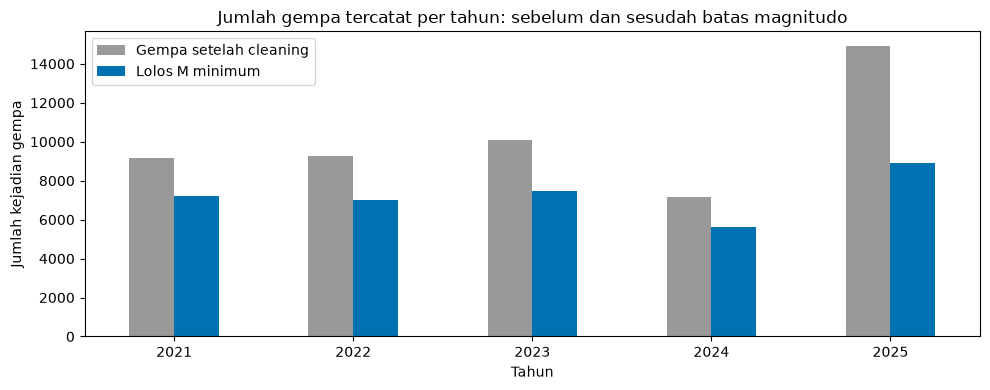

**Cara membaca:** pilih tahun, lalu bandingkan batang abu-abu (setelah cleaning) dengan biru (memenuhi batas magnitudo).
Median adalah nilai tengah setelah data diurutkan, berbeda dari rata-rata.

**Yang terlihat:** 2025 memiliki kejadian tercatat terbanyak pada data M minimal 3, yaitu 8.887 kejadian.
Ini menjelaskan isi katalog. Perubahan pencatatan atau cakupan sumber juga dapat memengaruhi jumlahnya,
sehingga kita belum dapat menyimpulkan wilayah menjadi lebih berbahaya.


In [3]:
annual, thresholds = eda(ROOT)
_, panel, train, _, _, _ = load_prepared(ROOT)
clean = pd.read_csv(ROOT / "data/processed/events_clean.csv")
historic = clean.loc[clean["year"].between(2021, 2025)].copy()
used = historic.loc[historic["magnitude"].ge(cfg["min_magnitude"])].copy()
jumlah = lambda value: f"{int(value):,}".replace(",", ".")
angka = lambda value: f"{value:.2f}".replace(".", ",")
display(Markdown(f"""### Data apa yang kita periksa?

EDA berarti **mengenali isi dan kondisi data sebelum membuat kelompok**.

| Data 2021-2025 | Jumlah | Satu baris berarti |
| --- | ---: | --- |
| Setelah cleaning, sebelum batas magnitudo | {jumlah(len(historic))} | Satu kejadian gempa |
| Memenuhi magnitudo minimal {cfg['min_magnitude']:g} | {jumlah(len(used))} | Satu kejadian gempa |
| Data training yang layak untuk clustering | {jumlah(len(train))} | Satu kotak selama satu triwulan |

Kita memeriksa katalog sebelum batas magnitudo untuk memahami pencatatannya,
kemudian memeriksa data yang benar-benar masuk penelitian.
**Data 2026 tidak disertakan dalam EDA ini.**
"""))
annual_view = annual[["n_events", "min_magnitude", "median_magnitude"]].copy()
annual_view["Lolos M minimum"] = used.groupby("year").size().reindex(annual_view.index, fill_value=0)
annual_view = annual_view.rename_axis("Tahun").reset_index().rename(columns={
    "n_events": "Gempa setelah cleaning", "min_magnitude": "M terkecil tercatat", "median_magnitude": "M tengah (median)"})
display(annual_view)
fig, ax = plt.subplots(figsize=(10, 4))
annual_view.set_index("Tahun")[["Gempa setelah cleaning", "Lolos M minimum"]].plot.bar(ax=ax, rot=0, color=["#999999", "#0072B2"])
ax.set(title="Jumlah gempa tercatat per tahun: sebelum dan sesudah batas magnitudo", xlabel="Tahun", ylabel="Jumlah kejadian gempa")
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/eda_annual_readable.png", dpi=160)
plt.show()
plt.close(fig)
year_max = used.groupby("year").size().idxmax()
display(Markdown(f"""**Cara membaca:** pilih tahun, lalu bandingkan batang abu-abu (setelah cleaning) dengan biru (memenuhi batas magnitudo).
Median adalah nilai tengah setelah data diurutkan, berbeda dari rata-rata.

**Yang terlihat:** {year_max} memiliki kejadian tercatat terbanyak pada data M minimal {cfg['min_magnitude']:g}, yaitu {jumlah(used.groupby('year').size().max())} kejadian.
Ini menjelaskan isi katalog. Perubahan pencatatan atau cakupan sumber juga dapat memengaruhi jumlahnya,
sehingga kita belum dapat menyimpulkan wilayah menjadi lebih berbahaya.
"""))
assert len(used) == train["earthquake_count"].sum()


<a id="s4"></a>
## 4. Apakah lima ciri aktivitas saling berkaitan?

Satu baris di sini adalah satu kotak-triwulan training. Lima cirinya: frekuensi gempa yang dipadatkan dengan log1p, rata-rata magnitudo, magnitudo terbesar, rata-rata kedalaman, serta proporsi kejadian dengan kedalaman kurang dari 70 km. Proporsi 0,8 berarti 80% kejadian berkedalaman valid termasuk dangkal. Tabel korelasi memperlihatkan hubungan antarciri, bukan akurasi model.

,Frekuensi (skala log),Rata-rata magnitudo,Magnitudo terbesar,Rata-rata kedalaman,Proporsi gempa dangkal
Frekuensi (skala log),1.00,-0.04,0.45,-0.10,0.03
Rata-rata magnitudo,-0.04,1.00,0.80,0.26,-0.22
Magnitudo terbesar,0.45,0.80,1.00,0.15,-0.15
Rata-rata kedalaman,-0.10,0.26,0.15,1.00,-0.75
Proporsi gempa dangkal,0.03,-0.22,-0.15,-0.75,1.00


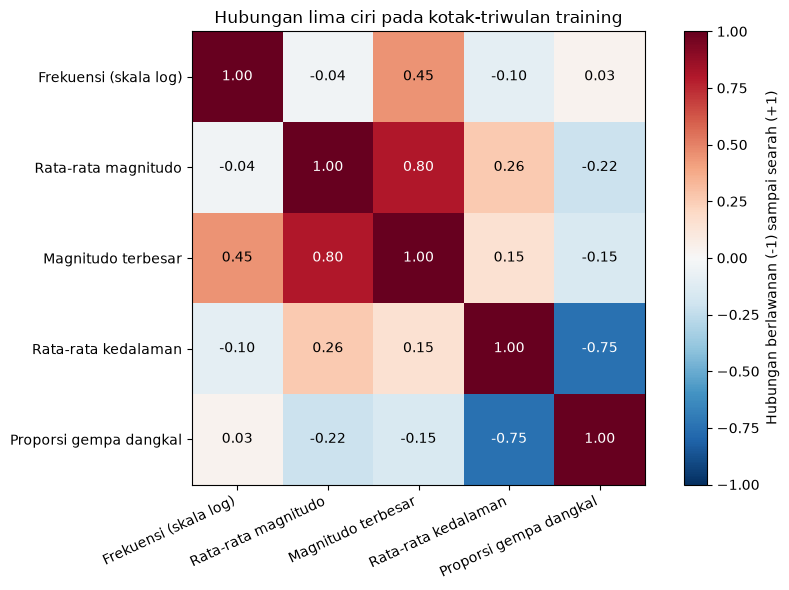

**Cara membaca:** angka mendekati +1 berarti dua ciri cenderung meningkat bersama;
angka mendekati -1 berarti arahnya berlawanan. Angka dekat 0 berarti hubungan lurusnya lemah.
Angka 1 pada diagonal hanya membandingkan ciri dengan dirinya sendiri.

**Hasil pada data ini:** rata-rata magnitudo dan magnitudo terbesar memiliki hubungan 0,80.
Rata-rata kedalaman dan proporsi gempa dangkal memiliki hubungan -0,75.
Pada data ini, kotak dengan rata-rata kedalaman lebih besar cenderung memiliki proporsi gempa dangkal lebih kecil.

**Artinya untuk model:** sebagian ciri membawa informasi yang saling berkaitan.
Menyetarakan skala angka tidak menghilangkan hubungan ini.
Korelasi juga tidak membuktikan hubungan sebab-akibat.


In [4]:
feature_names = {
    "log_frequency": "Frekuensi (skala log)", "avg_magnitude": "Rata-rata magnitudo",
    "max_magnitude": "Magnitudo terbesar", "avg_depth": "Rata-rata kedalaman",
    "shallow_fraction": "Proporsi gempa dangkal"}
corr = pd.read_csv(ROOT / "reports/evaluation/feature_correlation.csv", index_col=0)
display(corr.rename(index=feature_names, columns=feature_names).round(2))
fig, ax = plt.subplots(figsize=(9, 6))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
labels = [feature_names[key] for key in corr.columns]
ax.set_xticks(range(len(labels)), labels, rotation=25, ha="right")
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        value = corr.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", color="white" if abs(value) > .6 else "black")
fig.colorbar(image, ax=ax, label="Hubungan berlawanan (-1) sampai searah (+1)")
ax.set_title("Hubungan lima ciri pada kotak-triwulan training")
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/eda_correlation_readable.png", dpi=160)
plt.show()
plt.close(fig)
display(Markdown(f"""**Cara membaca:** angka mendekati +1 berarti dua ciri cenderung meningkat bersama;
angka mendekati -1 berarti arahnya berlawanan. Angka dekat 0 berarti hubungan lurusnya lemah.
Angka 1 pada diagonal hanya membandingkan ciri dengan dirinya sendiri.

**Hasil pada data ini:** rata-rata magnitudo dan magnitudo terbesar memiliki hubungan {angka(corr.loc['avg_magnitude', 'max_magnitude'])}.
Rata-rata kedalaman dan proporsi gempa dangkal memiliki hubungan {angka(corr.loc['avg_depth', 'shallow_fraction'])}.
Pada data ini, kotak dengan rata-rata kedalaman lebih besar cenderung memiliki proporsi gempa dangkal lebih kecil.

**Artinya untuk model:** sebagian ciri membawa informasi yang saling berkaitan.
Menyetarakan skala angka tidak menghilangkan hubungan ini.
Korelasi juga tidak membuktikan hubungan sebab-akibat.
"""))


<a id="s5"></a>
## 5. Seperti apa magnitudo, kedalaman, dan jumlah per triwulan?

Grafik bagian ini hanya memakai kejadian yang memenuhi batas magnitudo utama. Baca keterangan setelah grafik untuk memahami sumbu dan angka ringkasannya.

Grafik berikut memakai **36.146 kejadian dengan M minimal 3 pada 2021-2025**. Satu kejadian dapat dihitung satu kali dalam setiap grafik.

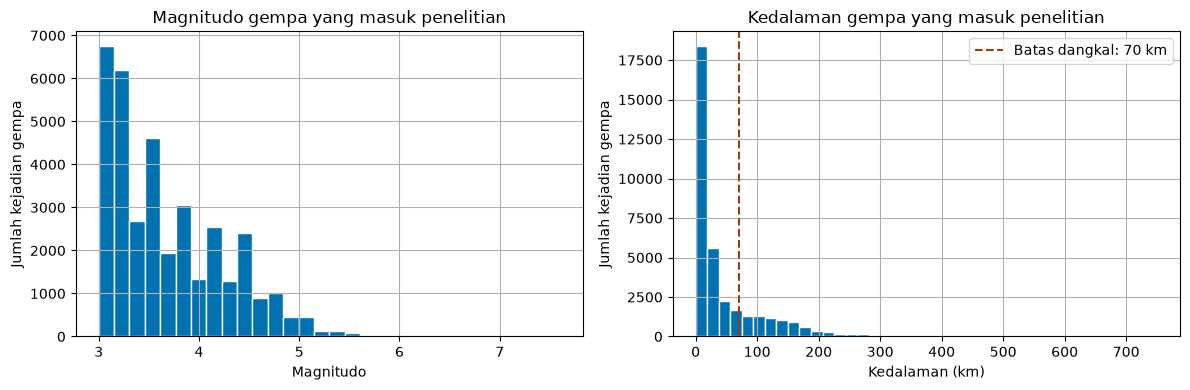

**Cara membaca:** batang yang lebih tinggi berarti lebih banyak gempa dalam rentang angka tersebut.
Grafik kiri menunjukkan magnitudo; grafik kanan menunjukkan kedalaman. Ketinggian batang adalah jumlah gempa, bukan tingkat bahaya.

**Ringkasan data yang masuk penelitian:** median magnitudo **3,60**,
median kedalaman **18,00 km**.
Dari 36.146 kejadian dengan kedalaman tersedia,
**76,04%** berada pada kedalaman kurang dari 70 km.


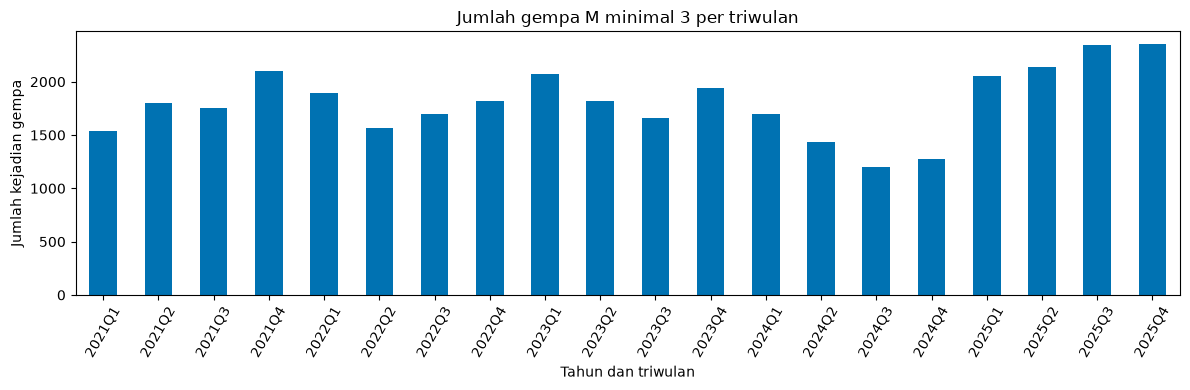

**Cara membaca:** Q1 = Januari-Maret, Q2 = April-Juni, Q3 = Juli-September, Q4 = Oktober-Desember. Grafik ini menunjukkan jumlah kejadian seluruh wilayah penelitian, bukan perubahan kelompok pada satu kotak. Perubahan kelompok per kotak diperiksa di notebook 07.

In [5]:
display(Markdown(f"Grafik berikut memakai **{jumlah(len(used))} kejadian dengan M minimal {cfg['min_magnitude']:g} pada 2021-2025**. Satu kejadian dapat dihitung satu kali dalam setiap grafik."))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
used["magnitude"].hist(ax=axes[0], bins=30, color="#0072B2", edgecolor="white")
axes[0].set(title="Magnitudo gempa yang masuk penelitian", xlabel="Magnitudo", ylabel="Jumlah kejadian gempa")
used["depth"].hist(ax=axes[1], bins=40, color="#0072B2", edgecolor="white")
axes[1].axvline(cfg["shallow_depth_km"], color="#9C3D10", linestyle="--", label=f"Batas dangkal: {cfg['shallow_depth_km']:g} km")
axes[1].set(title="Kedalaman gempa yang masuk penelitian", xlabel="Kedalaman (km)", ylabel="Jumlah kejadian gempa")
axes[1].legend()
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/eda_distributions_readable.png", dpi=160)
plt.show()
plt.close(fig)
valid_depth = used["depth"].dropna()
display(Markdown(f"""**Cara membaca:** batang yang lebih tinggi berarti lebih banyak gempa dalam rentang angka tersebut.
Grafik kiri menunjukkan magnitudo; grafik kanan menunjukkan kedalaman. Ketinggian batang adalah jumlah gempa, bukan tingkat bahaya.

**Ringkasan data yang masuk penelitian:** median magnitudo **{angka(used['magnitude'].median())}**,
median kedalaman **{angka(valid_depth.median())} km**.
Dari {jumlah(len(valid_depth))} kejadian dengan kedalaman tersedia,
**{angka(valid_depth.lt(cfg['shallow_depth_km']).mean() * 100)}%** berada pada kedalaman kurang dari {cfg['shallow_depth_km']:g} km.
"""))
quarters = used.groupby("period").size().reindex(pd.period_range("2021Q1", "2025Q4", freq="Q").astype(str), fill_value=0)
fig, ax = plt.subplots(figsize=(12, 4))
quarters.plot.bar(ax=ax, color="#0072B2", rot=60)
ax.set(title=f"Jumlah gempa M minimal {cfg['min_magnitude']:g} per triwulan", xlabel="Tahun dan triwulan", ylabel="Jumlah kejadian gempa")
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/eda_quarters_readable.png", dpi=160)
plt.show()
plt.close(fig)
display(Markdown("**Cara membaca:** Q1 = Januari-Maret, Q2 = April-Juni, Q3 = Juli-September, Q4 = Oktober-Desember. Grafik ini menunjukkan jumlah kejadian seluruh wilayah penelitian, bukan perubahan kelompok pada satu kotak. Perubahan kelompok per kotak diperiksa di notebook 07."))


<a id="s6"></a>
## 6. Apa pengaruh batas magnitudo terhadap jumlah data?

Batas minimal menentukan kejadian mana yang disertakan. Di sini kita membandingkan jumlah data, belum membandingkan hasil kelompok.

In [6]:
threshold_view = thresholds.pivot(index="year", columns="min_magnitude", values="event_count")
threshold_view.columns = [f"M minimal {value:g}" for value in threshold_view.columns]
display(threshold_view.rename_axis("Tahun").reset_index())
totals = thresholds.groupby("min_magnitude")["event_count"].sum()
display(Markdown(f"""**Cara membaca:** pada tahun yang sama, pilih kolom batas magnitudo yang berbeda.
M minimal 3 berarti magnitudo 3 ke atas, bukan hanya tepat 3.

Dengan batas utama **M minimal {cfg['min_magnitude']:g}**, data historis yang tersisa adalah **{jumlah(len(used))} kejadian**.
Jika batas dinaikkan menjadi M minimal 4, tersisa **{jumlah(totals.loc[4])} kejadian**.
Makin tinggi batasnya, makin sedikit data yang digunakan.

**Keputusan penelitian:** batas utama tetap mengikuti konfigurasi.
Tabel ini memperlihatkan pengaruh batas tersebut terhadap jumlah data;
tabel ini belum membuktikan bahwa semua gempa di atas batas itu tercatat lengkap.
Pengaruh perubahan batas terhadap hasil kelompok diuji di notebook 08.
"""))


,Tahun,M minimal 2.5,M minimal 3,M minimal 3.5,M minimal 4
0,2021,9148,7189,4343,2425
1,2022,9248,6984,4122,2366
2,2023,10066,7485,4380,2225
3,2024,7178,5601,3392,1805
4,2025,14913,8887,4271,2082


**Cara membaca:** pada tahun yang sama, pilih kolom batas magnitudo yang berbeda.
M minimal 3 berarti magnitudo 3 ke atas, bukan hanya tepat 3.

Dengan batas utama **M minimal 3**, data historis yang tersisa adalah **36.146 kejadian**.
Jika batas dinaikkan menjadi M minimal 4, tersisa **10.903 kejadian**.
Makin tinggi batasnya, makin sedikit data yang digunakan.

**Keputusan penelitian:** batas utama tetap mengikuti konfigurasi.
Tabel ini memperlihatkan pengaruh batas tersebut terhadap jumlah data;
tabel ini belum membuktikan bahwa semua gempa di atas batas itu tercatat lengkap.
Pengaruh perubahan batas terhadap hasil kelompok diuji di notebook 08.


<a id="s7"></a>
## 7. Apakah setiap kotak memiliki cukup banyak kejadian?

Jumlah gempa berbeda dari jumlah baris model. Bagian ini memeriksa berapa kejadian yang mendasari ringkasan satu kotak selama tiga bulan.

In [7]:
historical_panel = panel.loc[panel["split"].eq("train")]
empty_count = int(historical_panel["state"].eq("NO_EVENTS").sum())
few = train["earthquake_count"].between(1, cfg["low_support_count"] - 1)
display(Markdown(f"""### Berapa banyak data di dalam setiap kotak?

| Ringkasan historis | Jumlah |
| --- | ---: |
| Kotak geografis yang pernah aktif | {jumlah(historical_panel['grid_id'].nunique())} |
| Triwulan yang diperiksa | {jumlah(historical_panel['period'].nunique())} |
| Seluruh baris kotak-triwulan | {jumlah(len(historical_panel))} |
| Baris tanpa kejadian pada triwulan tersebut | {jumlah(empty_count)} |
| Baris yang layak masuk model | {jumlah(len(train))} |
| Baris training dengan 1-{cfg['low_support_count'] - 1} gempa | {jumlah(few.sum())} ({angka(few.mean() * 100)}%) |

**Contoh:** satu kotak dengan 10 gempa pada Januari-Maret adalah satu baris model dengan jumlah gempa 10.
Kotak yang sama pada April-Juni menjadi baris lain.

**Temuan yang perlu diperhatikan:** banyak baris hanya merangkum sedikit kejadian.
Jika sebuah baris hanya memiliki satu gempa, rata-rata dan maksimum magnitudonya sama dengan magnitudo gempa itu.
Karena itu perubahan profil dapat dipengaruhi sedikit kejadian, dan tidak langsung membuktikan perubahan kondisi tektonik.
Kepekaan hasil terhadap jumlah kejadian diuji di notebook 08.
"""))
support = pd.cut(train["earthquake_count"], bins=[0, 1, 4, 9, float("inf")], labels=["1 gempa", "2-4 gempa", "5-9 gempa", "10 gempa atau lebih"])
display(support.value_counts(sort=False).rename_axis("Gempa dalam satu kotak-triwulan").reset_index(name="Jumlah baris training"))
display(train[["grid_id", "period", "earthquake_count", "avg_magnitude", "max_magnitude", "avg_depth"]].head(5).rename(columns={
    "grid_id": "ID kotak", "period": "Triwulan", "earthquake_count": "Jumlah gempa", "avg_magnitude": "Rata-rata M", "max_magnitude": "M terbesar", "avg_depth": "Rata-rata kedalaman (km)"}).round(2))


### Berapa banyak data di dalam setiap kotak?

| Ringkasan historis | Jumlah |
| --- | ---: |
| Kotak geografis yang pernah aktif | 1.758 |
| Triwulan yang diperiksa | 20 |
| Seluruh baris kotak-triwulan | 35.160 |
| Baris tanpa kejadian pada triwulan tersebut | 21.689 |
| Baris yang layak masuk model | 13.471 |
| Baris training dengan 1-4 gempa | 11.662 (86,57%) |

**Contoh:** satu kotak dengan 10 gempa pada Januari-Maret adalah satu baris model dengan jumlah gempa 10.
Kotak yang sama pada April-Juni menjadi baris lain.

**Temuan yang perlu diperhatikan:** banyak baris hanya merangkum sedikit kejadian.
Jika sebuah baris hanya memiliki satu gempa, rata-rata dan maksimum magnitudonya sama dengan magnitudo gempa itu.
Karena itu perubahan profil dapat dipengaruhi sedikit kejadian, dan tidak langsung membuktikan perubahan kondisi tektonik.
Kepekaan hasil terhadap jumlah kejadian diuji di notebook 08.


,Gempa dalam satu kotak-triwulan,Jumlah baris training
0,1 gempa,6739
1,2-4 gempa,4923
2,5-9 gempa,1374
3,10 gempa atau lebih,435


,ID kotak,Triwulan,Jumlah gempa,Rata-rata M,M terbesar,Rata-rata kedalaman (km)
0,-10_-10,2021Q2,1,3.20,3.2,13.0
1,-10_-12,2022Q4,1,4.10,4.1,10.0
2,-10_-12,2025Q2,1,3.70,3.7,10.0
3,-10_-13,2023Q2,1,3.20,3.2,10.0
4,-10_-14,2021Q2,2,3.85,4.4,90.5


<a id="s8"></a>
## 8. Apakah data kosong dan pencatatan sudah diperiksa?

Kita memeriksa nilai yang hilang, perubahan puncak histogram, dan jenis magnitudo dari sumber. Pemeriksaan ini membantu mengenali keterbatasan; tidak membuktikan katalog mencatat seluruh gempa yang terjadi.

In [8]:
missing = historic[["time", "latitude", "longitude", "magnitude", "depth"]].isna().sum()
display(missing.rename_axis("Kolom").reset_index(name="Nilai kosong setelah cleaning").replace({"Kolom": {"time": "Waktu", "latitude": "Lintang", "longitude": "Bujur", "magnitude": "Magnitudo", "depth": "Kedalaman"}}))
diagnostic = pd.read_csv(ROOT / "reports/evaluation/completeness_diagnostic.csv")
display(diagnostic[["year", "max_curvature_histogram_mode", "analysis_threshold"]].rename(columns={
    "year": "Tahun", "max_curvature_histogram_mode": "Magnitudo paling sering (bin 0,1)", "analysis_threshold": "Batas M penelitian"}).round(1))
display(Markdown("**Cara membaca:** magnitudo paling sering adalah puncak histogram dengan rentang 0,1. Perbedaan antartahun menjadi alasan untuk memeriksa konsistensi katalog. Angka ini bukan bukti bahwa katalog sudah lengkap. Tidak ada nilai kosong juga tidak berarti semua gempa yang terjadi berhasil dicatat."))
types = pd.read_csv(ROOT / "reports/evaluation/magnitude_types.csv")
display(types.pivot_table(index="year", columns="magnitude_type", values="n", aggfunc="sum", fill_value=0).rename_axis(index="Tahun", columns="Jenis M dari sumber").reset_index())
display(Markdown("**Jenis magnitudo:** kolom `m`, `mb`, `ml`, `mla`, dan `mw` adalah kode yang disediakan katalog. Data ini memuat beberapa jenis magnitudo dan belum disetarakan ke satu skala Mw. Karena itu, istilah yang digunakan dalam penelitian adalah magnitudo katalog, bukan seluruhnya Mw."))


,Kolom,Nilai kosong setelah cleaning
0,Waktu,0
1,Lintang,0
2,Bujur,0
3,Magnitudo,0
4,Kedalaman,0


,Tahun,"Magnitudo paling sering (bin 0,1)",Batas M penelitian
0,2021,3.1,3.0
1,2022,3.0,3.0
2,2023,3.0,3.0
3,2024,3.0,3.0
4,2025,2.5,3.0


**Cara membaca:** magnitudo paling sering adalah puncak histogram dengan rentang 0,1. Perbedaan antartahun menjadi alasan untuk memeriksa konsistensi katalog. Angka ini bukan bukti bahwa katalog sudah lengkap. Tidak ada nilai kosong juga tidak berarti semua gempa yang terjadi berhasil dicatat.

Jenis M dari sumber,Tahun,m,mb,ml,mla,mw
0,2021,7852,1172,2,0,122
1,2022,7775,1362,3,0,108
2,2023,8936,1009,6,1,118
3,2024,6300,804,1,0,79
4,2025,13924,887,6,0,105


**Jenis magnitudo:** kolom `m`, `mb`, `ml`, `mla`, dan `mw` adalah kode yang disediakan katalog. Data ini memuat beberapa jenis magnitudo dan belum disetarakan ke satu skala Mw. Karena itu, istilah yang digunakan dalam penelitian adalah magnitudo katalog, bukan seluruhnya Mw.

<a id="s9"></a>
## 9. Kesimpulan EDA dan langkah berikutnya

Ringkasan ini menghubungkan isi data dengan kehati-hatian yang diperlukan saat membaca hasil K-Means dan DBSCAN.

In [9]:
display(Markdown(f"""### Apa yang kita ketahui setelah EDA?

1. Ada **{jumlah(len(used))} kejadian historis** yang memenuhi batas M minimal {cfg['min_magnitude']:g}.
   Kejadian ini diringkas menjadi **{jumlah(len(train))} baris training kotak-triwulan**.
2. Jumlah tercatat berbeda antartahun. Itu adalah pola dalam katalog, belum penjelasan penyebab fisiknya.
3. Beberapa ciri saling berkaitan, terutama rata-rata dan maksimum magnitudo, serta kedalaman dan proporsi dangkal.
4. **{angka(few.mean() * 100)}% baris training** hanya memiliki 1-{cfg['low_support_count'] - 1} gempa,
   sehingga profil dan perubahannya perlu ditafsirkan hati-hati.
5. Pilihan batas magnitudo memengaruhi data yang tersisa. Kelengkapan katalog dan perbedaan jenis magnitudo masih menjadi batas interpretasi.

**Langkah berikutnya:** notebook 04 dan 05 mengelompokkan kotak-triwulan berdasarkan lima ciri aktivitas.
EDA belum menghasilkan kelompok dan belum menghasilkan peta tingkat risiko.
Hasil clustering serta uji sensitivitas dibaca bersama temuan EDA ini.

### Buka tabel lengkap
"""))
for filename in ["catalogue_by_year.csv", "magnitude_threshold_audit.csv", "feature_correlation.csv", "completeness_diagnostic.csv", "magnitude_types.csv"]:
    display(FileLink(str(ROOT / "reports/evaluation" / filename)))


### Apa yang kita ketahui setelah EDA?

1. Ada **36.146 kejadian historis** yang memenuhi batas M minimal 3.
   Kejadian ini diringkas menjadi **13.471 baris training kotak-triwulan**.
2. Jumlah tercatat berbeda antartahun. Itu adalah pola dalam katalog, belum penjelasan penyebab fisiknya.
3. Beberapa ciri saling berkaitan, terutama rata-rata dan maksimum magnitudo, serta kedalaman dan proporsi dangkal.
4. **86,57% baris training** hanya memiliki 1-4 gempa,
   sehingga profil dan perubahannya perlu ditafsirkan hati-hati.
5. Pilihan batas magnitudo memengaruhi data yang tersisa. Kelengkapan katalog dan perbedaan jenis magnitudo masih menjadi batas interpretasi.

**Langkah berikutnya:** notebook 04 dan 05 mengelompokkan kotak-triwulan berdasarkan lima ciri aktivitas.
EDA belum menghasilkan kelompok dan belum menghasilkan peta tingkat risiko.
Hasil clustering serta uji sensitivitas dibaca bersama temuan EDA ini.

### Buka tabel lengkap


C:\Users\yudhi\Documents\machine-learning\seismic_research_2021_2025\reports\evaluation\catalogue_by_year.csv

C:\Users\yudhi\Documents\machine-learning\seismic_research_2021_2025\reports\evaluation\magnitude_threshold_audit.csv

C:\Users\yudhi\Documents\machine-learning\seismic_research_2021_2025\reports\evaluation\feature_correlation.csv

C:\Users\yudhi\Documents\machine-learning\seismic_research_2021_2025\reports\evaluation\completeness_diagnostic.csv

C:\Users\yudhi\Documents\machine-learning\seismic_research_2021_2025\reports\evaluation\magnitude_types.csv

## Referensi dan batas interpretasi

[Dokumentasi EMSC](https://www.seismicportal.eu/fdsn-wsevent.html), [clustering scikit-learn](https://scikit-learn.org/stable/modules/clustering.html), dan docs/metodologi.md. Hasil adalah profil aktivitas katalog dalam bounding box dan periode yang dipilih. Interpretasi risiko, prediksi kejadian gempa, serta klaim perubahan fisik memerlukan bukti tambahan.